# Import Library Torch dan Proses Pengecekan Device
---
Baris ini digunakan untuk memanggil *library* PyTorch dan memverifikasi apakah environment Google Colab saat ini berjalan menggunakan akselerasi GPU NVIDIA (CUDA) atau hanya mengandalkan CPU dengan nilai *boolean*. Jika, nilainya `True` maka GPU NVIDIA, sedangkan nilai `false` berarti CPU.

In [ ]:
import torch

print("CUDA Status :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name :", torch.cuda.get_device_name(0))
else:
    print("Perangkat masih menggunakan CPU")

CUDA Status : True
Device Name : Tesla T4


# Import Library
---
Baris ini berisikan library yang digunakan selama proses pembuatan model AI, mulai dari `os` agar Python dapat berinteraksi dengan sistem operasi. Kemudian, `pandas` untuk manipulasi dan analisis data, `numpy` untuk komputasi numerikal, `matplotlib.pyplot` dan `seaborn` untuk membuat visualisasi data berupa grafik garis, diagram batang, dan lain-lain.

Lalu ada `cv2` untuk untuk mengolah gambar dan video, `re` untuk melacak teks, serta `shutil` untuk melakukan copy-paste, memindahkan, atau menghapus file dan folder dengan mudah.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import re
import shutil

### Pengambilan dataset tingkat kematangan kakao (*cocoa ripeness*) dari Kaggle menggunakan kagglehub, yang kemudian disalin ke folder proyek lokal menggunakan shutil agar siap untuk diolah.
---

In [ ]:
import kagglehub

temp_path = kagglehub.dataset_download("juanfelipeheredia/cocoa-ripeness-dataset-tcs-01")

target_path = "./data/cocoa-ripeness"

shutil.copytree(temp_path, target_path, dirs_exist_ok=True)

print("Dataset berhasil disimpan di:", target_path)

100%|██████████| 44.1M/44.1M [00:01<00:00, 23.9MB/s]

Extracting files...


Dataset berhasil disimpan di: ./data/cocoa-ripeness


### Pengelompokan dataset gambar ke dalam folder terpisah berdasarkan kategori kematangannya (Immature, Mature, Overmature) dengan mendeteksi kode huruf pada nama file menggunakan Regex, lalu menyalin file tersebut ke foldernya masing-masing menggunakan shutil.
---

In [ ]:
source_dir = f"{target_path}"
output_dir = "./dataset_grouped"

label_map = {
    'I': 'Immature',
    'M': 'Mature',
    'S': 'Overmature'
}

count = 0

for root, dirs, files in os.walk(source_dir):
    for filename in files:
        if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
            # Ekstrak huruf prefix
            match = re.match(r"^([a-zA-Z]+)", filename)

            if match:
                code = match.group(1).upper()
                label_name = label_map.get(code, "Unknown")

                # Buat folder target berdasarkan label
                target_folder = os.path.join(output_dir, label_name)
                os.makedirs(target_folder, exist_ok=True)

                # Salin gambar dari lokasi aslinya (root) ke folder tujuan
                src_file = os.path.join(root, filename)
                dst_file = os.path.join(target_folder, filename)

                shutil.copy(src_file, dst_file)
                count += 1

print("Pengelompokkan folder selesai!")

Pengelompokkan folder selesai!


### Mengubah daftar lokasi file gambar (filepath) dan labelnya (Immature, Mature, Overmature) yang sudah dikelompokkan sebelumnya ke dalam format tabel data dan menampilkan visualisasi perbandingan jumlah data untuk masing-masing kategori kematangan dalam bentuk diagram batang.
---

--- Contoh Baris Data ---


,filename,filepath,label
467,M50.jpg,./dataset_grouped/Mature/M50.jpg,Mature
33,I141.jpg,./dataset_grouped/Immature/I141.jpg,Immature
131,I14.jpg,./dataset_grouped/Immature/I14.jpg,Immature
72,I173.jpg,./dataset_grouped/Immature/I173.jpg,Immature
78,I144.jpg,./dataset_grouped/Immature/I144.jpg,Immature
113,I242.jpg,./dataset_grouped/Immature/I242.jpg,Immature
274,S95.jpg,./dataset_grouped/Overmature/S95.jpg,Overmature
185,I46.jpg,./dataset_grouped/Immature/I46.jpg,Immature
261,I3.jpg,./dataset_grouped/Immature/I3.jpg,Immature
9,I211.jpg,./dataset_grouped/Immature/I211.jpg,Immature


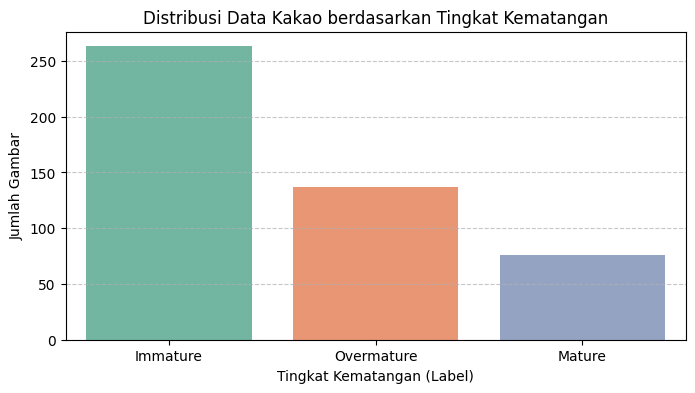

In [ ]:
data = []

for label_name in os.listdir(output_dir):
    label_path = os.path.join(output_dir, label_name)

    if os.path.isdir(label_path):
        for filename in os.listdir(label_path):
            if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                filepath = os.path.join(label_path, filename)

                data.append({
                    'filename': filename,
                    'filepath': filepath,
                    'label': label_name
                })

df = pd.DataFrame(data)

print("--- Contoh Baris Data ---")
display(df.sample(10, random_state=42))

# jumlah gambar per kategori/label
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='label', hue='label', palette='Set2', legend=False)
plt.title('Distribusi Data Kakao berdasarkan Tingkat Kematangan')
plt.xlabel('Tingkat Kematangan (Label)')
plt.ylabel('Jumlah Gambar')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Membagi *dataset* menjadi bagian utama, `train`(60%) sebagai bahan model belajar, `validation`(20%) untuk bahan evaluasi model ketika proses pembelajaran sehingga model mengetahui apakah ia sudah belajar dengan benar dan mencegah terjadinya overfitting, serta `test`(20%) sebagai bahan ujian akhir yang isinya data baru dan relevan di dunia nyata.
---

In [ ]:
from sklearn.model_selection import train_test_split

# Lokasi folder asal dan folder tujuan pemisahan
source_grouped_dir = "./dataset_grouped"
output_split_dir = "./dataset_split"

# Kumpulkan semua path file dan label dari folder dataset_grouped
data_paths = []
for label_name in os.listdir(source_grouped_dir):
    label_path = os.path.join(source_grouped_dir, label_name)
    if os.path.isdir(label_path):
        for filename in os.listdir(label_path):
            if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                filepath = os.path.join(label_path, filename)
                data_paths.append((filepath, label_name))

df_paths = pd.DataFrame(data_paths, columns=['filepath', 'label'])

# Stratified Split
train_val_df, test_df = train_test_split(
    df_paths,
    test_size=0.20,
    stratify=df_paths['label'],
    random_state=42
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.25,
    stratify=train_val_df['label'],
    random_state=42
)

# Fungsi untuk menyalin file ke struktur folder baru
def copy_files(dataframe, split_name):
    for _, row in dataframe.iterrows():
        src = row['filepath']
        label = row['label']
        filename = os.path.basename(src)

        dst_dir = os.path.join(output_split_dir, split_name, label)
        os.makedirs(dst_dir, exist_ok=True)

        dst = os.path.join(dst_dir, filename)
        shutil.copy(src, dst)

copy_files(train_df, 'train')
copy_files(val_df, 'val')
copy_files(test_df, 'test')

print("Pemisahan dataset selesai!\n")

summary_df = pd.DataFrame({
    'Train (60%)': train_df['label'].value_counts(),
    'Validation (20%)': val_df['label'].value_counts(),
    'Test (20%)': test_df['label'].value_counts()
})
display(summary_df)

Pemisahan dataset selesai!



,Train (60%),Validation (20%),Test (20%)
label,,,
Immature,157,53,53
Overmature,82,27,28
Mature,46,15,15


### Melakukan preprocessing dataset menggunakan modul transforms untuk augmentasi data latih guna meningkatkan variasi dan mencegah overfitting. Selain itu, Weighted Random Sampler untuk menangani ketidakseimbangan jumlah data antar kelas.
---

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms

# augmentasi acak agar model belajar variasi posisi, rotasi, & warna
train_transforms = transforms.Compose([
    transforms.Resize((505, 505)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Data Validation & Test
val_test_transforms = transforms.Compose([
    transforms.Resize((505, 505)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(root='./dataset_split/train', transform=train_transforms)
val_dataset   = datasets.ImageFolder(root='./dataset_split/val', transform=val_test_transforms)
test_dataset  = datasets.ImageFolder(root='./dataset_split/test', transform=val_test_transforms)

targets = train_dataset.targets

# Hitung jumlah sampel di setiap kelas
class_sample_count = np.bincount(targets)
print(f"Jumlah sampel per kelas di Training: {class_sample_count}")

# Hitung bobot per kelas
class_weights = 1.0 / class_sample_count
print(f"Bobot per kelas: {class_weights}")

sample_weights = [class_weights[t] for t in targets]

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(sample_weights),
    replacement=True
)

# DataLoader
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2
)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("\nDataLoader berhasil dibuat dan siap digunakan untuk training!")

Jumlah sampel per kelas di Training: [157  46  82]
Bobot per kelas: [0.00636943 0.02173913 0.01219512]

DataLoader berhasil dibuat dan siap digunakan untuk training!


### Mengecek isi dari satu kelompok data (*batch*) pertama untuk menghitung jumlah masing-masing kategori kematangan kakao, guna memastikan data sudah dikelompokkan dengan benar dan siap dipelajari oleh model.
---

In [ ]:
images, labels = next(iter(train_loader))

unique, counts = np.unique(labels.numpy(), return_counts=True)
class_names = train_dataset.classes

print("Distribusi kelas dalam 1 Batch Training:")
for idx, count in zip(unique, counts):
    print(f"- {class_names[idx]}: {count} gambar")

Distribusi kelas dalam 1 Batch Training:
- Immature: 9 gambar
- Mature: 8 gambar
- Overmature: 15 gambar


# Uji Coba Model 1: ResNet18


In [ ]:
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")

# Load Pre-trained Model (ResNet18)
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 3)

model = model.to(device)

# Loss Function & Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training Loop
EPOCHS = 20

# Tempat penyimpanan checkpoint
checkpoint_dir = "./checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)
best_model_path = os.path.join(checkpoint_dir, "best_resnet18_cocoa.pth")

best_val_acc = 0.0

for epoch in range(EPOCHS):
    # PHASE TRAINING
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels.data)
        total_train += labels.size(0)

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = correct_train.double() / total_train

    # PHASE VALIDATION
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += torch.sum(preds == labels.data)
            total_val += labels.size(0)

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val.double() / total_val

    # Cetak Progress
    print(f"Epoch [{epoch+1}/{EPOCHS}] "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} "
          f"| Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}")

    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': best_val_acc,
            'val_loss': epoch_val_loss
        }, best_model_path)
        print(f"  --> Checkpoint disimpan! (Val Acc Meningkat: {best_val_acc:.4f})")

print("\nPelatihan Selesai!")

Menggunakan device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 176MB/s]


Epoch [1/20] Train Loss: 0.8252 | Train Acc: 0.6351 | Val Loss: 3.7959 | Val Acc: 0.4947
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.4947)
Epoch [2/20] Train Loss: 0.4189 | Train Acc: 0.8000 | Val Loss: 34.0800 | Val Acc: 0.3053
Epoch [3/20] Train Loss: 0.4673 | Train Acc: 0.8035 | Val Loss: 1.5117 | Val Acc: 0.7895
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.7895)
Epoch [4/20] Train Loss: 0.4123 | Train Acc: 0.8456 | Val Loss: 2.0429 | Val Acc: 0.4421
Epoch [5/20] Train Loss: 0.3312 | Train Acc: 0.8737 | Val Loss: 4.2828 | Val Acc: 0.2842
Epoch [6/20] Train Loss: 0.1690 | Train Acc: 0.9333 | Val Loss: 0.2677 | Val Acc: 0.9263
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.9263)
Epoch [7/20] Train Loss: 0.2616 | Train Acc: 0.8947 | Val Loss: 0.2199 | Val Acc: 0.9053
Epoch [8/20] Train Loss: 0.2558 | Train Acc: 0.8982 | Val Loss: 0.6581 | Val Acc: 0.8842
Epoch [9/20] Train Loss: 0.2970 | Train Acc: 0.8982 | Val Loss: 2.2132 | Val Acc: 0.6632
Epoch [10/20] Train Loss: 0.1759 

### Tips Praktis: Menggunakan Timestamp untuk Nama Checkpoint Unik
---
Dengan menggunakan modul `datetime`, nama file *checkpoint* akan dibuat dinamis berdasarkan waktu saat model tersebut disimpan. Hal ini mencegah model terbaik dari hasil *run* sebelumnya tertimpa secara tidak sengaja.

# Proses Menyimpan Hasil Train Ke Drive

In [ ]:
from google.colab import drive
import shutil

drive.mount('/content/drive')

src = './checkpoints/best_resnet18_cocoa.pth'
dst = '/content/drive/MyDrive/Matkul AI/Cocoa/Checkpoints'

shutil.copy(src, dst)
print("Berhasil disimpan ke Google Drive!")

Mounted at /content/drive
Berhasil disimpan ke Google Drive!


### Melakukan evaluasi performa model dengan memuat model terbaik hasil pelatihan, melakukan prediksi pada data uji, serta memvisualisasikan hasil evaluasinya ke dalam bentuk Classification Report, Confusion Matrix, dan grafik batang untuk menganalisis akurasi tebakan model pada setiap kelas kematangan kakao.
---

Model berhasil dimuat dari Epoch 14 (Val Acc: 0.9474)

              CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Immature     0.9811    0.9811    0.9811        53
      Mature     0.8750    0.9333    0.9032        15
  Overmature     1.0000    0.9643    0.9818        28

    accuracy                         0.9688        96
   macro avg     0.9520    0.9596    0.9554        96
weighted avg     0.9701    0.9688    0.9692        96



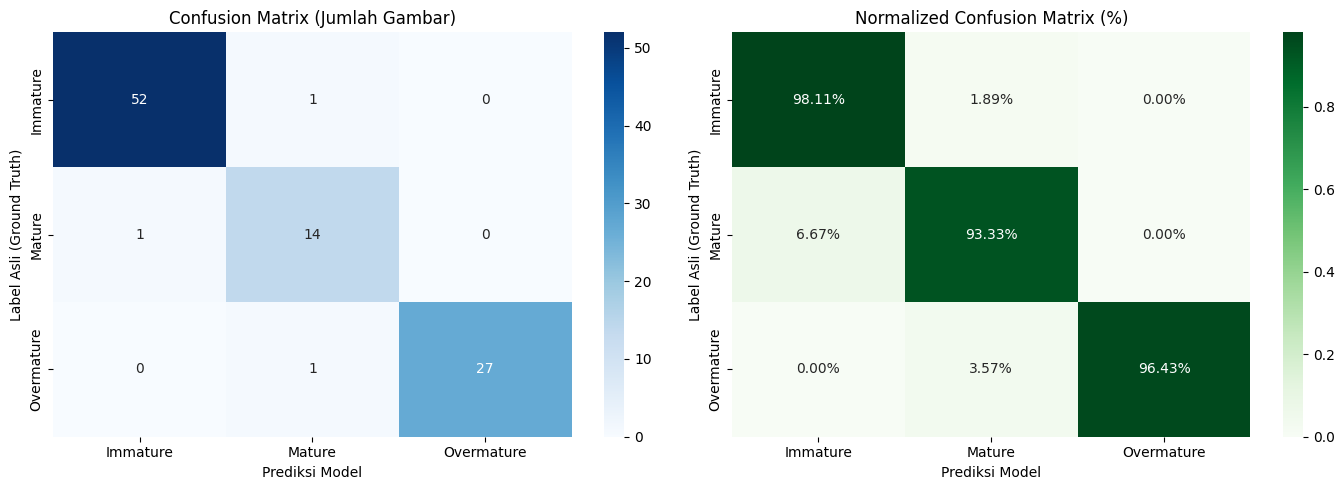

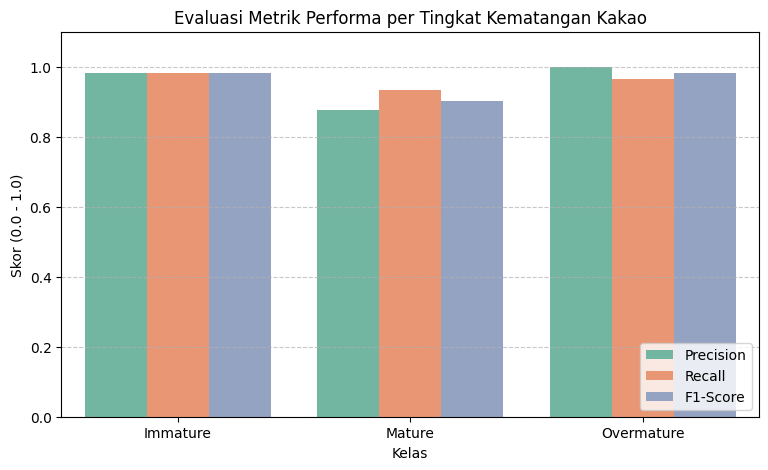

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score, precision_recall_fscore_support

# Load Checkpoint Model Terbaik
checkpoint_path = './checkpoints/best_resnet18_cocoa.pth'
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)
model.eval()

print(f"Model berhasil dimuat dari Epoch {checkpoint['epoch']} (Val Acc: {checkpoint['val_acc']:.4f})")

# Prediksi pada Test Set
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names = test_dataset.classes  # ['Immature', 'Mature', 'Overmature']

# CLASSIFICATION REPORT
print("\n" + "="*50)
print("              CLASSIFICATION REPORT")
print("="*50)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# CONFUSION MATRIX (Normalized & Raw)
cm = confusion_matrix(all_labels, all_preds)
cm_norm = confusion_matrix(all_labels, all_preds, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriks 1: Jumlah Asli (Counts)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix (Jumlah Gambar)')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Label Asli (Ground Truth)')

# Matriks 2: Persentase (Normalized)
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Normalized Confusion Matrix (%)')
axes[1].set_xlabel('Prediksi Model')
axes[1].set_ylabel('Label Asli (Ground Truth)')

plt.tight_layout()
plt.show()

# CHART PERFORMA METRIK PER KELAS (F1-Score, Precision, Recall)
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average=None)

metrics_df = {
    'Kelas': class_names * 3,
    'Nilai': np.concatenate([precision, recall, f1]),
    'Metrik': ['Precision']*len(class_names) + ['Recall']*len(class_names) + ['F1-Score']*len(class_names)
}

import pandas as pd
df_metrics = pd.DataFrame(metrics_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=df_metrics, x='Kelas', y='Nilai', hue='Metrik', palette='Set2')
plt.title('Evaluasi Metrik Performa per Tingkat Kematangan Kakao')
plt.ylim(0, 1.1)
plt.ylabel('Skor (0.0 - 1.0)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.show()

### Uji Coba Model Alternatif: EfficientNet-B0
---
Bagian ini menambahkan model EfficientNet-B0 sebagai pembanding ResNet18.
Semua variabel pakai suffix `_effnet` supaya tidak menimpa variabel ResNet18.

In [ ]:
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")

# Load Pre-trained Model (EfficientNet-B0)
model_effnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

# Ganti classifier head sesuai jumlah kelas (Immature, Mature, Overmature)
num_features_effnet = model_effnet.classifier[1].in_features
model_effnet.classifier[1] = nn.Linear(num_features_effnet, 3)

model_effnet = model_effnet.to(device)

# Loss Function & Optimizer (terpisah dari punya ResNet18)
criterion_effnet = nn.CrossEntropyLoss()
optimizer_effnet = optim.Adam(model_effnet.parameters(), lr=0.001)

# Training Loop
EPOCHS_EFFNET = 20

checkpoint_dir = "./checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)
best_model_path_effnet = os.path.join(checkpoint_dir, "best_efficientnet_b0_cocoa.pth")

best_val_acc_effnet = 0.0

for epoch in range(EPOCHS_EFFNET):
    # PHASE TRAINING
    model_effnet.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model_effnet(images)
        loss = criterion_effnet(outputs, labels)

        optimizer_effnet.zero_grad()
        loss.backward()
        optimizer_effnet.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels.data)
        total_train += labels.size(0)

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = correct_train.double() / total_train

    # PHASE VALIDATION
    model_effnet.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_effnet(images)
            loss = criterion_effnet(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += torch.sum(preds == labels.data)
            total_val += labels.size(0)

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val.double() / total_val

    print(f"[EfficientNet-B0] Epoch [{epoch+1}/{EPOCHS_EFFNET}] "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} "
          f"| Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}")

    if epoch_val_acc > best_val_acc_effnet:
        best_val_acc_effnet = epoch_val_acc
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model_effnet.state_dict(),
            'optimizer_state_dict': optimizer_effnet.state_dict(),
            'val_acc': best_val_acc_effnet,
            'val_loss': epoch_val_loss
        }, best_model_path_effnet)
        print(f"  --> Checkpoint disimpan! (Val Acc Meningkat: {best_val_acc_effnet:.4f})")

print("\nPelatihan EfficientNet-B0 Selesai!")

Menggunakan device: cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 83.9MB/s]


[EfficientNet-B0] Epoch [1/20] Train Loss: 0.5699 | Train Acc: 0.7263 | Val Loss: 0.9167 | Val Acc: 0.7474
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.7474)
[EfficientNet-B0] Epoch [2/20] Train Loss: 0.2436 | Train Acc: 0.9123 | Val Loss: 0.3360 | Val Acc: 0.8947
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.8947)
[EfficientNet-B0] Epoch [3/20] Train Loss: 0.1596 | Train Acc: 0.9579 | Val Loss: 0.1323 | Val Acc: 0.9684
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.9684)
[EfficientNet-B0] Epoch [4/20] Train Loss: 0.0725 | Train Acc: 0.9825 | Val Loss: 0.3327 | Val Acc: 0.9368
[EfficientNet-B0] Epoch [5/20] Train Loss: 0.0448 | Train Acc: 0.9825 | Val Loss: 0.2039 | Val Acc: 0.9579
[EfficientNet-B0] Epoch [6/20] Train Loss: 0.0333 | Train Acc: 0.9930 | Val Loss: 0.1362 | Val Acc: 0.9579
[EfficientNet-B0] Epoch [7/20] Train Loss: 0.0905 | Train Acc: 0.9684 | Val Loss: 0.4101 | Val Acc: 0.9053
[EfficientNet-B0] Epoch [8/20] Train Loss: 0.0279 | Train Acc: 0.9930 | Val Loss: 0.33

# Proses Menyimpan Hasil Train Ke Drive

In [ ]:
from google.colab import drive
import shutil
import os

try:
    # Menjalankan mount dengan force_remount untuk menyegarkan sesi
    drive.mount('/content/drive', force_remount=True)

    src_effnet = './checkpoints/best_efficientnet_b0_cocoa.pth'
    dst_dir = '/content/drive/MyDrive/Matkul AI/Cocoa/Checkpoints'

    # Memastikan folder tujuan ada di Drive
    if not os.path.exists(dst_dir):
        os.makedirs(dst_dir, exist_ok=True)

    dst_effnet = os.path.join(dst_dir, 'best_efficientnet_b0_cocoa.pth')

    if os.path.exists(src_effnet):
        shutil.copy(src_effnet, dst_effnet)
        print("✅ Berhasil! Checkpoint EfficientNet-B0 disimpan ke Google Drive.")
    else:
        print(f"⚠️ Error: File {src_effnet} tidak ditemukan di sistem lokal.")

except Exception as e:
    print(f"❌ Gagal menyambungkan ke Drive: {e}")
    print("Tips: Pastikan cookie pihak ketiga diizinkan di browser Anda dan pop-up tidak diblokir.")

Mounted at /content/drive
✅ Berhasil! Checkpoint EfficientNet-B0 disimpan ke Google Drive.


### Melakukan evaluasi performa model dengan memuat model terbaik hasil pelatihan, melakukan prediksi pada data uji, serta memvisualisasikan hasil evaluasinya ke dalam bentuk Classification Report, Confusion Matrix, dan grafik batang untuk menganalisis akurasi tebakan model pada setiap kelas kematangan kakao.
---

Model EfficientNet-B0 berhasil dimuat dari Epoch 3 (Val Acc: 0.9684)

       CLASSIFICATION REPORT (EfficientNet-B0)
              precision    recall  f1-score   support

    Immature     1.0000    0.9811    0.9905        53
      Mature     0.8750    0.9333    0.9032        15
  Overmature     0.9643    0.9643    0.9643        28

    accuracy                         0.9688        96
   macro avg     0.9464    0.9596    0.9527        96
weighted avg     0.9701    0.9688    0.9692        96



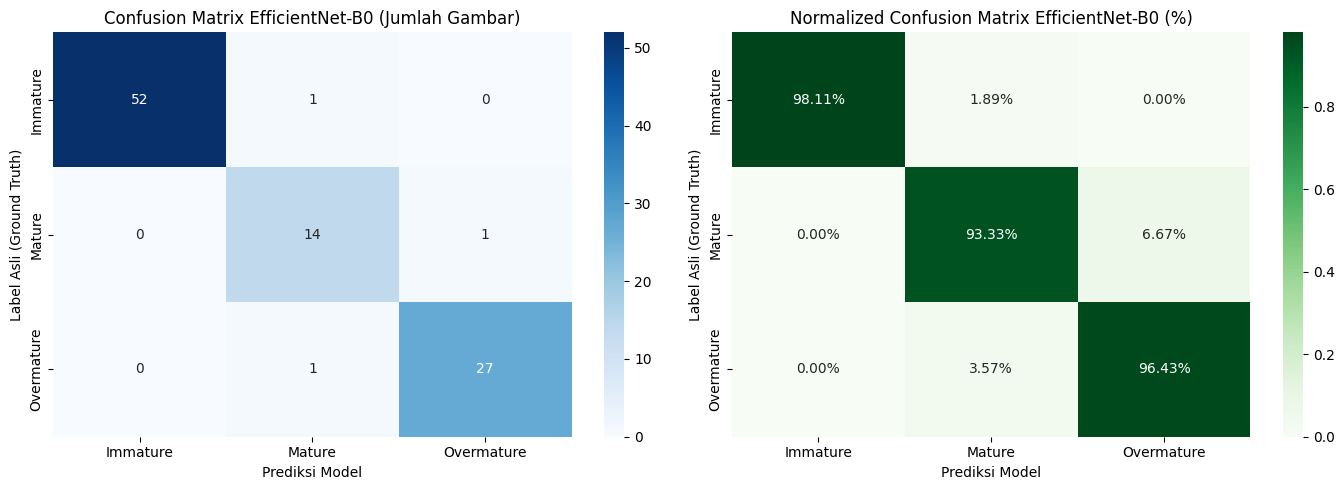

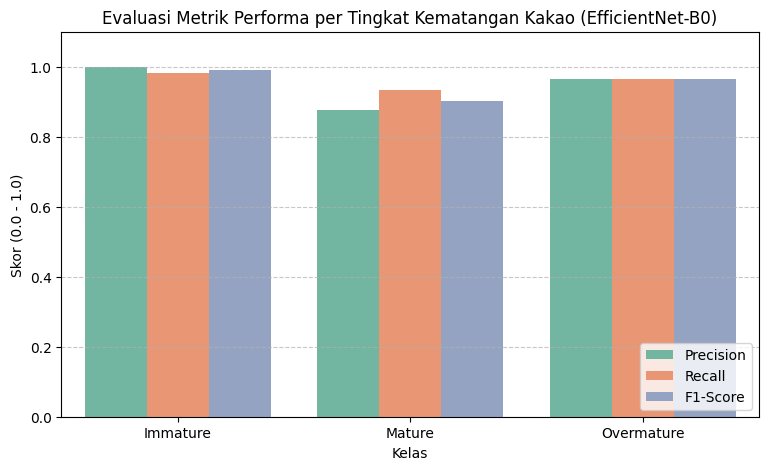

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score, precision_recall_fscore_support

checkpoint_path_effnet = './checkpoints/best_efficientnet_b0_cocoa.pth'
checkpoint_effnet = torch.load(checkpoint_path_effnet)
model_effnet.load_state_dict(checkpoint_effnet['model_state_dict'])
model_effnet.to(device)
model_effnet.eval()

print(f"Model EfficientNet-B0 berhasil dimuat dari Epoch {checkpoint_effnet['epoch']} (Val Acc: {checkpoint_effnet['val_acc']:.4f})")

all_preds_effnet = []
all_labels_effnet = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_effnet(images)
        _, preds = torch.max(outputs, 1)

        all_preds_effnet.extend(preds.cpu().numpy())
        all_labels_effnet.extend(labels.numpy())

class_names = test_dataset.classes

print("\n" + "="*50)
print("       CLASSIFICATION REPORT (EfficientNet-B0)")
print("="*50)
print(classification_report(all_labels_effnet, all_preds_effnet, target_names=class_names, digits=4))

cm_effnet = confusion_matrix(all_labels_effnet, all_preds_effnet)
cm_norm_effnet = confusion_matrix(all_labels_effnet, all_preds_effnet, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_effnet, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix EfficientNet-B0 (Jumlah Gambar)')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Label Asli (Ground Truth)')

sns.heatmap(cm_norm_effnet, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Normalized Confusion Matrix EfficientNet-B0 (%)')
axes[1].set_xlabel('Prediksi Model')
axes[1].set_ylabel('Label Asli (Ground Truth)')

plt.tight_layout()
plt.show()

precision_effnet, recall_effnet, f1_effnet, _ = precision_recall_fscore_support(all_labels_effnet, all_preds_effnet, average=None)

metrics_df_effnet = {
    'Kelas': class_names * 3,
    'Nilai': np.concatenate([precision_effnet, recall_effnet, f1_effnet]),
    'Metrik': ['Precision']*len(class_names) + ['Recall']*len(class_names) + ['F1-Score']*len(class_names)
}

df_metrics_effnet = pd.DataFrame(metrics_df_effnet)

plt.figure(figsize=(9, 5))
sns.barplot(data=df_metrics_effnet, x='Kelas', y='Nilai', hue='Metrik', palette='Set2')
plt.title('Evaluasi Metrik Performa per Tingkat Kematangan Kakao (EfficientNet-B0)')
plt.ylim(0, 1.1)
plt.ylabel('Skor (0.0 - 1.0)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.show()